# RoughNet revision: regenerate and extend Figure 5

This notebook answers two requests.

1. **Tessa:** *"Here is the retrained final model. Can you rerun your generation of Figure 5?"* Part A loads `final_roughnet_model.pth` with the RoughNet repo code. It regenerates the prediction tiles, using the same `pred_tiles/pred_XXXXX.tif` layout that `AnalyseDiffusionTessa.ipynb` reads, and redraws the single-patch Figure 5 (Tuktoyaktuk patch 12556).
2. **Reviewers:** R2 Major 5 says Fig. 5 is a single patch and cannot support global log-normal claims. R2 Major 3 and R1 Major 1 ask for region-aggregated σ, variogram range and task-oriented validation. Part B repeats the Fig. 5 analysis on **every patch in every region**. It produces a region-aggregated table, a multi-panel "Figure 5 extended" and a check of how representative patch 12556 is.

**Changes from the original analysis cells (please review):**
* **Validity mask.** LiDAR patches carry a validity band (band 2). Invalid pixels in band 1 are stored as `0.0`, not `< -100`. The old `raw > -100` test therefore counted gaps as valid zero-elevation pixels, which adds a spurious spike at 0 m and biases σ low. Prediction tiles cover the full 256×256 window, including gaps. This notebook uses one **joint mask** for GT and prediction: band 2 > 0.5, and finite and > -100 in both. Old 1-band tiles fall back to the previous rule.
* **Two kinds of "JSD".** The JSD in the Fig. 5 summary box is `scipy.spatial.distance.jensenshannon` between a patch histogram and a fitted parametric PDF. It is a natural-log JS *distance* that measures fit quality. Tables 1–2 report a base-2 JS *divergence* between GT and prediction histograms (repo `recon_metrics`). The two are kept apart below as `fitJSD_*` (Fig. 5 style) and `jsd_gt_pred` (Table style, 1 m scale).

Run on Colab. Part A needs a GPU runtime. Part B is CPU-only.

## 0. Configuration (edit paths here)

In [2]:
import os, re, json, glob, math, hashlib, warnings
import numpy as np
warnings.filterwarnings('ignore')

# Colab: mount Drive (no-op elsewhere)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

DRIVE    = '/content/drive/MyDrive/Colab Notebooks/Tessa'
REPO_DIR = '/content/RoughNet'                         # git clone target (Part A + split file)
CKPT_PATH = f'{DRIVE}/final_roughnet_model.pth'        # the retrained model Tessa shared
OUT_DIR  = f'{DRIVE}/Fig5_extended'

# GT LiDAR patches (2-band: residual, validity) and Sentinel-2 patch folders (s2_patch_XXXXX/t0..t5.tif + attrs.json).
# S2 folders are only needed for Part A (inference). Folder names must contain 'pondinlet'/'cambridge' (repo uses them for image-age dates).
REGIONS = {
    'pondinlet': dict(name='Pond Inlet',    role='validation', lidar_dir=f'{DRIVE}/Input/lidar_patches_pondinlet', s2_dir=f'{DRIVE}/Input/s2_patches_pondinlet'),
    'tuk':       dict(name='Tuktoyaktuk',   role='validation', lidar_dir=f'{DRIVE}/Input/lidar_patches_tuk',       s2_dir=f'{DRIVE}/Input/s2_patches_tuk'),
    'cambridge': dict(name='Cambridge Bay', role='test',       lidar_dir=f'{DRIVE}/Input/lidar_patches_cambridge', s2_dir=f'{DRIVE}/Input/s2_patches_cambridge'),
}

# Prediction sets to analyse. 'submitted' = tiles behind the submitted paper; 'final' = written by Part A from final_roughnet_model.pth.
PRED_SETS = {
    'submitted': {r: f'{DRIVE}/Prediction/cosine_plms_{r}/pred_tiles' for r in REGIONS},
    'final':     {r: f'{DRIVE}/Prediction/final_model_plms_{r}/pred_tiles' for r in REGIONS},
}
MAIN_SET = 'final'                 # set used for the extended figure

FIG5_REGION, FIG5_PID = 'tuk', '12556'
RESTRICT_TO_SPLIT = True           # analyse only the repo's clean cohorts (PI val 1,122 / Tuk val 168 / CB test 2,111)
SPLIT_JSON = f'{REPO_DIR}/splits/train_val_split_ids.json'

# Task-oriented proxies (placeholders: agree thresholds with the team, e.g. Segal et al. 2020 / Johnson et al. 2022 bins)
SIGMA_CLASS_EDGES  = [0.0, 0.05, 0.10, 0.20, np.inf]       # m, RMS-height classes
SIGMA_CLASS_LABELS = ['smooth\n<5 cm', 'low\n5-10 cm', 'moderate\n10-20 cm', 'rough\n>20 cm']
RIDGE_H = 0.35                     # m above patch mean -> "ridge" pixel (same 0.35 m transition as TestDistribFits)

MAD_K = 50.0                       # robust outlier clip on GT, as in the original cells
MIN_VALID = 2000                   # skip patches with fewer jointly valid pixels
VARIO_N_BULK, VARIO_N_FIG5 = 2000, 5000
N_WORKERS = max(1, (os.cpu_count() or 2))
os.makedirs(OUT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Part A: inference with `final_roughnet_model.pth` (GPU)

The checkpoint plugs into the repo's own model code. Training (`scripts/main.py`) saves `{'model_state_dict', 'config', 'epoch', 'val_loss'}`. The `config` holds the schedule (cosine), `context_k` (6), channels (64), attention (mid) and so on. The cell below prints what is inside. It also handles a bare `state_dict` by falling back to `splits/original_clean.yaml`.

Sampling is cosine PLMS with 1,000 steps. The initial noise uses the repo's `paired_noise(region, tile_id, 42)`, the same seeding as the repo's noise/sampler and conditioning studies. With the same checkpoint, these tiles should therefore match the repo's cached study predictions.

**Equivalent CLI** (repo checkout with `input_data/{s2,lidar}_patches_{region}`): `python scripts/evaluation.py --region tuk --sampler plms --checkpoint /path/final_roughnet_model.pth`. Tiles land in `figures/original_clean/final_val_tuk_plms/pred_tiles/`. That route draws unseeded noise, so the in-notebook route below is preferred for reproducibility.

**Rough cost** (1,000 PLMS steps, batch 8, T4): ~1 min per batch. That is ~20 min for Tuk (168 patches), ~2.5 h for Pond Inlet and ~4.5 h for Cambridge Bay. The run resumes after a disconnect: tiles already written are skipped. For Fig. 5 alone, run just `['12556']` (about one minute).

In [4]:
# A1. Setup (Colab): clone the repo and install the one extra dependency
import subprocess, sys
if not os.path.isdir(REPO_DIR):
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/tessacannon48/RoughNet', REPO_DIR], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio'], check=False)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
print(subprocess.run(['git', '-C', REPO_DIR, 'log', '-1', '--format=%h %ci %s'], capture_output=True, text=True).stdout)

dd528d1 2026-10-11 03:29:55 +0100 Remove superseded quick conditioning probe outputs



In [5]:
# A2. Inspect the checkpoint and build the model exactly as the repo does
import torch, yaml
from src.model.unet import ConditionalUNet
from src.diffusion.scheduler import LinearDiffusionScheduler, CosineDiffusionScheduler

def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

def load_roughnet(ckpt_path, device):
    ck = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    if isinstance(ck, dict) and 'model_state_dict' in ck:
        state, cfg = ck['model_state_dict'], ck.get('config')
        meta = {k: ck.get(k) for k in ('epoch', 'val_loss')}
    elif isinstance(ck, torch.nn.Module):
        state, cfg, meta = ck.state_dict(), None, {}
    elif isinstance(ck, dict) and all(torch.is_tensor(v) for v in ck.values()):
        state, cfg, meta = ck, None, {}
    else:
        raise ValueError(f'Unrecognised checkpoint structure: {type(ck)} keys={list(ck)[:10] if isinstance(ck, dict) else None}')
    if cfg is None:
        cfg = yaml.safe_load(open(os.path.join(REPO_DIR, 'splits', 'original_clean.yaml')))
        print('WARNING: checkpoint has no config -> assuming splits/original_clean.yaml (cosine, k=6, 64 ch, mid attention)')
    k = cfg['training']['context_k']
    model = ConditionalUNet(in_channels=1, cond_channels=4 * k, attr_dim=8 * k,
                            base_channels=cfg['model']['base_channels'], embed_dim=cfg['model']['embed_dim'],
                            unet_depth=cfg['model']['unet_depth'], attention_variant=cfg['model']['attention_variant'],
                            cond_k=k).to(device)
    model.load_state_dict(state, strict=True)   # fails loudly if the architecture does not match
    model.eval()
    T = cfg['training']['timesteps']
    sched = (CosineDiffusionScheduler if cfg['training']['noise_schedule'] == 'cosine' else LinearDiffusionScheduler)(timesteps=T, device=device)
    return model, sched, cfg, meta

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
MODEL, SCHED, CFG, META = load_roughnet(CKPT_PATH, DEVICE)
print(f"device={DEVICE} | sha256={sha256_file(CKPT_PATH)[:16]}... | epoch={META.get('epoch')} val_loss={META.get('val_loss')}")
print(f"schedule={CFG['training']['noise_schedule']} T={CFG['training']['timesteps']} context_k={CFG['training']['context_k']} "
      f"base={CFG['model']['base_channels']} attn={CFG['model']['attention_variant']} split_digest={CFG['data'].get('split_digest', 'n/a')}")

device=cuda | sha256=53f42e1075573b43... | epoch=166 val_loss=0.003447856786402149
schedule=cosine T=1000 context_k=6 base=64 attn=mid split_digest=c4fbdd8b7df144c5be8a4ed65c1cbe111e9184dd8e7c5ea9fb9394b8f8e865b5


In [6]:
# A3. Predict a list of patches and write GeoTIFFs named pred_<id>.tif (resumable)
import rasterio
from torch.utils.data import DataLoader
from src.data.dataset import LidarS2Dataset
from src.diffusion.sampling import p_sample_loop_plms
from src.utils.conditioning_ablation import paired_noise

def cohort_ids(region):
    s = json.load(open(SPLIT_JSON))[region]
    return list(s['test' if REGIONS[region]['role'] == 'test' else 'validation'])

def write_pred_tif(ref_lidar_tif, out_path, arr):
    with rasterio.open(ref_lidar_tif) as ref:
        prof = ref.profile.copy()
    prof.update(dtype='float32', count=1, nodata=-9999.0, compress='deflate', predictor=3)
    arr = np.where(np.isfinite(arr), arr, -9999.0).astype(np.float32)
    tmp = out_path + '.tmp.tif'
    with rasterio.open(tmp, 'w', **prof) as dst:
        dst.write(arr, 1)
    os.replace(tmp, out_path)

@torch.no_grad()
def predict_tiles(region, pids, out_dir, replicates=(42,), batch_size=8, suffix_replicate=False):
    os.makedirs(out_dir, exist_ok=True)
    def out_name(pid, r):
        return os.path.join(out_dir, f'pred_{pid}_r{r}.tif' if suffix_replicate else f'pred_{pid}.tif')
    todo = [p for p in pids if any(not os.path.exists(out_name(p, r)) for r in replicates)]
    print(f'{region}: {len(pids) - len(todo)} done, {len(todo)} to predict -> {out_dir}')
    if not todo:
        return
    k = CFG['training']['context_k']
    ds = LidarS2Dataset(REGIONS[region]['lidar_dir'], REGIONS[region]['s2_dir'], context_k=k,
                        randomize_context=False, augment=False, split='val', split_pids=todo)
    missing = set(todo) - {s['tile_id'] for s in ds.samples}
    if missing:
        print(f'  WARNING: {len(missing)} ids lack S2/LiDAR inputs, e.g. {sorted(missing)[:5]}')
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=2)
    from tqdm.auto import tqdm
    for batch in tqdm(loader, desc=region):
        ids = list(batch['tile_id'])
        for r in replicates:
            noise = paired_noise(region, ids, r, (1, 256, 256)).to(DEVICE)
            s2, attrs = batch['s2'].to(DEVICE), batch['attrs'].to(DEVICE)
            pred = p_sample_loop_plms(MODEL, SCHED, noise.shape, s2, attrs, DEVICE, initial_noise=noise)
            pred = (pred + batch['lidar_patch_mean'].to(DEVICE).view(-1, 1, 1, 1)).float().cpu().numpy()
            for i, pid in enumerate(ids):
                write_pred_tif(ds.samples[[s['tile_id'] for s in ds.samples].index(pid)]['lidar_path'], out_name(pid, r), pred[i, 0])

# Fig. 5 patch first (about 1 min on GPU), then the full cohorts (long; resumable)
predict_tiles(FIG5_REGION, [FIG5_PID], PRED_SETS['final'][FIG5_REGION])
RUN_FULL_COHORTS = False           # set True to regenerate every region
if RUN_FULL_COHORTS:
    for region in ['tuk', 'pondinlet', 'cambridge']:
        predict_tiles(region, cohort_ids(region), PRED_SETS['final'][region])

tuk: 0 done, 1 to predict -> /content/drive/MyDrive/Colab Notebooks/Tessa/Prediction/final_model_plms_tuk/pred_tiles
Prepared 0 matched LiDAR↔S2 groups (k=6).


tuk: 0it [00:00, ?it/s]

In [7]:
# A4. (Optional, R1 Major 1) Stochastic ensemble for the Fig. 5 patch:
#     the same conditioning with N different initial noises shows how much sigma/range vary
#     between realisations, i.e. the "image-conditioned stochastic realisation" framing
ENSEMBLE_DIR = f'{OUT_DIR}/ensemble_{FIG5_REGION}_{FIG5_PID}'
ENSEMBLE_REPLICATES = [42] + list(range(1, 10))      # 10 members; 42 = the canonical member
RUN_ENSEMBLE = True
if RUN_ENSEMBLE:
    predict_tiles(FIG5_REGION, [FIG5_PID], ENSEMBLE_DIR, replicates=ENSEMBLE_REPLICATES, suffix_replicate=True)

tuk: 0 done, 1 to predict -> /content/drive/MyDrive/Colab Notebooks/Tessa/Fig5_extended/ensemble_tuk_12556
Prepared 0 matched LiDAR↔S2 groups (k=6).


tuk: 0it [00:00, ?it/s]

## Part B: per-patch statistics for every region (CPU)

For each GT/prediction pair, using the joint mask:

* RMS height σ, skewness, kurtosis and ridge fraction (fraction > `RIDGE_H` above the patch mean).
* Exponential-variogram effective range, fitted exactly as in the original cells.
* An ACF e-folding length as a fit-free check on spatial scale.
* Fig. 5-style best parametric family (Normal / Skew / Gamma / Log-normal) and its fit-JSD.
* GT-vs-prediction JS divergence (base 2, 256 shared bins; the Tables' definition at 1 m) and Wasserstein-1 distance.
* σ roughness class.

Pooled histograms and mean semivariograms are also kept for region-level comparisons. Results are cached per (set, region) in `OUT_DIR`.

In [8]:
# B1. Analysis library
import rasterio
from scipy import stats
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist, jensenshannon
from concurrent.futures import ProcessPoolExecutor
import pandas as pd

FAMILIES = ['Normal', 'Skew', 'Gamma', 'Log-normal']
H_EDGES = np.arange(-2.0, 3.0 + 1e-9, 0.01)          # pooled-PDF bins (m)
LAG_EDGES = np.arange(0, 200 + 4.0, 4.0)
LAG_CENTERS = LAG_EDGES[:-1] + 2.0
POOL_PER_PATCH = 400                                  # pixels per patch kept for pooled family fits

def patch_id(path):
    m = re.findall(r'(\d{5})', os.path.basename(path))
    return m[-1] if m else ''.join(filter(str.isdigit, os.path.basename(path))).zfill(5)

def read_pair(gt_path, pr_path, mad_k=MAD_K):
    with rasterio.open(gt_path) as s:
        gt_all = s.read().astype(np.float32)
    with rasterio.open(pr_path) as s:
        pr = s.read(1).astype(np.float32)
    gt = gt_all[0]
    valid_gt = (gt_all[1] > 0.5) if gt_all.shape[0] >= 2 else (gt > -100)
    joint = valid_gt & np.isfinite(gt) & (gt > -100) & np.isfinite(pr) & (pr > -100)
    if joint.sum() > 10 and mad_k:
        med = np.median(gt[joint]); mad = np.median(np.abs(gt[joint] - med))
        if mad > 0:
            joint &= np.abs(gt - med) <= mad_k * mad
    return gt, pr, joint

def exp_variogram(h, nugget, sill, eff_range):
    return nugget + sill * (1 - np.exp(-3 * h / eff_range))

def compute_variogram(img, mask, n_samples=VARIO_N_BULK, pixel_res=1.0, seed=42):
    vals = img[mask]; y, x = np.where(mask)
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(vals), size=min(n_samples, len(vals)), replace=False)
    d = pdist(np.column_stack((x[idx], y[idx])) * pixel_res)
    sq = 0.5 * pdist(vals[idx][:, None], metric='sqeuclidean')
    b = np.digitize(d, LAG_EDGES)
    sv = np.array([sq[b == i].mean() if np.any(b == i) else np.nan for i in range(1, len(LAG_EDGES))])
    ok = np.isfinite(sv)
    p0 = [np.nanmin(sv), np.nanmax(sv) - np.nanmin(sv), 50.0]
    try:
        popt, _ = curve_fit(exp_variogram, LAG_CENTERS[ok], sv[ok], p0=p0, bounds=([0, 0, 0], [np.inf, np.inf, 400.0]))
    except Exception:
        popt = np.array(p0)
    return sv, popt

def acf_efold_length(z, m, max_lag=128):
    # Masked FFT autocorrelation, radially averaged; first lag where ACF < 1/e (m). NaN if not reached.
    z = np.where(m, z - z[m].mean(), 0.0); w = m.astype(float)
    H, W = z.shape; s = (2 * H, 2 * W)
    num = np.fft.irfft2(np.abs(np.fft.rfft2(z, s)) ** 2, s)
    den = np.fft.irfft2(np.abs(np.fft.rfft2(w, s)) ** 2, s)
    with np.errstate(invalid='ignore', divide='ignore'):
        acf = np.where(den > 0.05 * den[0, 0], num / den, np.nan)
    acf = acf / acf[0, 0]
    iy = np.fft.fftfreq(s[0]) * s[0]; ix = np.fft.fftfreq(s[1]) * s[1]
    r = np.hypot(iy[:, None], ix[None, :]).round().astype(int)
    sel = (r <= max_lag) & np.isfinite(acf)
    prof = np.bincount(r[sel], acf[sel], minlength=max_lag + 1) / np.maximum(np.bincount(r[sel], minlength=max_lag + 1), 1)
    below = np.where(prof < 1 / np.e)[0]
    if len(below) == 0:
        return np.nan
    j = below[0]
    return float(j - 1 + (prof[j - 1] - 1 / np.e) / (prof[j - 1] - prof[j])) if j > 0 else 0.0

def family_pdf(name, params, x, shift):
    if name == 'Normal':  return stats.norm.pdf(x, *params)
    if name == 'Skew':    return stats.skewnorm.pdf(x, *params)
    if name == 'Gamma':   return stats.gamma.pdf(x + shift, *params)
    return stats.lognorm.pdf(x + shift, *params)

def fit_families(data, n_fit=5000, seed=42):
    # Fig. 5 procedure: MLE fits (on a 5k subsample for speed), fit-JSD = scipy JS distance on 100-bin histogram
    shift = np.abs(np.min(data)) + 0.01
    rng = np.random.RandomState(seed)
    d = data[rng.choice(len(data), n_fit, replace=False)] if len(data) > n_fit else data
    fits = {'Normal': stats.norm.fit(d), 'Skew': stats.skewnorm.fit(d),
            'Gamma': stats.gamma.fit(d + shift), 'Log-normal': stats.lognorm.fit(d + shift)}
    hist, e = np.histogram(data, bins=100, density=True); c = 0.5 * (e[:-1] + e[1:])
    p_emp = hist / hist.sum()
    out = {}
    for name, p in fits.items():
        y = family_pdf(name, p, c, shift)
        q = (y + 1e-10) / np.sum(y + 1e-10)
        out[name] = dict(params=[float(v) for v in p], jsd=float(jensenshannon(p_emp, q)))
    best = min(out, key=lambda k: out[k]['jsd'])
    return out, best, shift

def jsd_base2(a, b, bins=256):
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    e = np.linspace(lo, hi if hi > lo else lo + 1, bins + 1)
    p = np.histogram(a, e)[0].astype(float) + 1e-12; q = np.histogram(b, e)[0].astype(float) + 1e-12
    p /= p.sum(); q /= q.sum(); m = 0.5 * (p + q)
    return float(0.5 * (np.sum(p * np.log2(p / m)) + np.sum(q * np.log2(q / m))))

def sigma_class(s):
    return int(np.digitize(s, SIGMA_CLASS_EDGES[1:-1]))

def analyse_pair(args):
    gt_path, pr_path, region, pid = args
    try:
        gt, pr, m = read_pair(gt_path, pr_path)
        n = int(m.sum())
        if n < MIN_VALID:
            return dict(region=region, pid=pid, n_valid=n, skipped=True)
        g = gt[m] - gt[m].mean(); p = pr[m] - pr[m].mean()
        G = np.where(m, gt - gt[m].mean(), 0.0); P = np.where(m, pr - pr[m].mean(), 0.0)
        sv_g, v_g = compute_variogram(G, m); sv_p, v_p = compute_variogram(P, m)
        f_g, best_g, _ = fit_families(g); f_p, best_p, _ = fit_families(p)
        rng = np.random.RandomState(int(pid) if pid.isdigit() else 0)
        k = rng.choice(n, min(POOL_PER_PATCH, n), replace=False)
        sub = np.random.RandomState(1).choice(n, min(20000, n), replace=False)
        row = dict(region=region, pid=pid, n_valid=n, skipped=False,
                   sigma_gt=float(g.std()), sigma_pr=float(p.std()),
                   skew_gt=float(stats.skew(g)), skew_pr=float(stats.skew(p)),
                   kurt_gt=float(stats.kurtosis(g)), kurt_pr=float(stats.kurtosis(p)),
                   ridge_gt=float((g > RIDGE_H).mean()), ridge_pr=float((p > RIDGE_H).mean()),
                   range_gt=float(v_g[2]), range_pr=float(v_p[2]), sill_gt=float(v_g[1]), sill_pr=float(v_p[1]),
                   nugget_gt=float(v_g[0]), nugget_pr=float(v_p[0]),
                   acfL_gt=acf_efold_length(gt, m), acfL_pr=acf_efold_length(pr, m),
                   best_gt=best_g, best_pr=best_p,
                   jsd_gt_pred=jsd_base2(g, p), w1_gt_pred=float(stats.wasserstein_distance(g[sub], p[sub])),
                   rmse=float(np.sqrt(np.mean((g - p) ** 2))))
        for fam in FAMILIES:
            row[f'fitJSD_{fam}_gt'] = f_g[fam]['jsd']; row[f'fitJSD_{fam}_pr'] = f_p[fam]['jsd']
        row['class_gt'], row['class_pr'] = sigma_class(row['sigma_gt']), sigma_class(row['sigma_pr'])
        arrays = dict(hist_gt=np.histogram(g, H_EDGES)[0], hist_pr=np.histogram(p, H_EDGES)[0],
                      sv_gt=sv_g, sv_pr=sv_p, pool_gt=g[k].astype(np.float32), pool_pr=p[k].astype(np.float32))
        return row, arrays
    except Exception as e:
        return dict(region=region, pid=pid, skipped=True, error=repr(e))

def list_pairs(pred_dir, region):
    pairs = []
    for f in sorted(glob.glob(os.path.join(pred_dir, '*.tif'))):
        pid = patch_id(f)
        gt = os.path.join(REGIONS[region]['lidar_dir'], f'lidar_patch_{pid}.tif')
        if os.path.exists(gt):
            pairs.append((gt, f, region, pid))
    if RESTRICT_TO_SPLIT and os.path.exists(SPLIT_JSON):
        keep = set(json.load(open(SPLIT_JSON))[region]['test' if REGIONS[region]['role'] == 'test' else 'validation'])
        pairs = [p for p in pairs if p[3] in keep]
    return pairs

def run_set(set_name, force=False):
    frames, arrays = [], {}
    for region, pred_dir in PRED_SETS[set_name].items():
        csv = f'{OUT_DIR}/patch_stats_{set_name}_{region}.csv'; npz = csv.replace('.csv', '.npz')
        if os.path.exists(csv) and os.path.exists(npz) and not force:
            frames.append(pd.read_csv(csv, dtype={'pid': str})); arrays[region] = dict(np.load(npz)); continue
        pairs = list_pairs(pred_dir, region)
        if not pairs:
            print(f'[{set_name}] {region}: no prediction tiles in {pred_dir}'); continue
        rows, acc = [], dict(hist_gt=0, hist_pr=0, sv_gt=[], sv_pr=[], pool_gt=[], pool_pr=[])
        from tqdm.auto import tqdm
        with ProcessPoolExecutor(N_WORKERS) as ex:
            for res in tqdm(ex.map(analyse_pair, pairs, chunksize=4), total=len(pairs), desc=f'{set_name}:{region}'):
                if isinstance(res, tuple):
                    row, a = res; rows.append(row)
                    acc['hist_gt'] = acc['hist_gt'] + a['hist_gt']; acc['hist_pr'] = acc['hist_pr'] + a['hist_pr']
                    for kk in ('sv_gt', 'sv_pr', 'pool_gt', 'pool_pr'):
                        acc[kk].append(a[kk])
                else:
                    rows.append(res)
        df = pd.DataFrame(rows); df['set'] = set_name
        arr = dict(hist_gt=np.asarray(acc['hist_gt']), hist_pr=np.asarray(acc['hist_pr']),
                   sv_gt=np.vstack(acc['sv_gt']), sv_pr=np.vstack(acc['sv_pr']),
                   pool_gt=np.concatenate(acc['pool_gt']), pool_pr=np.concatenate(acc['pool_pr']))
        df.to_csv(csv, index=False); np.savez_compressed(npz, **arr)
        n_err = int(df.get('error', pd.Series(dtype=object)).notna().sum())
        print(f'[{set_name}] {region}: {int((~df.skipped).sum())} analysed, {int(df.skipped.sum())} skipped ({n_err} errors)')
        frames.append(df); arrays[region] = arr
    return (pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()), arrays

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 289, in _feed
    queue_sem.release()
    ~~~~~~~~~~~~~~~~~^^
ValueError: semaphore or lock released too ma

In [9]:
# B2. Sanity check: what does the GT validity band look like, and how much did the old '> -100' rule mis-count?
for region, cfgR in REGIONS.items():
    files = sorted(glob.glob(os.path.join(cfgR['lidar_dir'], 'lidar_patch_*.tif')))[:50]
    if not files:
        print(region, ': no LiDAR patches found'); continue
    nb, gap_as_valid = [], []
    for f in files:
        with rasterio.open(f) as s:
            a = s.read(); nb.append(a.shape[0])
            if a.shape[0] >= 2:
                gap_as_valid.append(np.mean((a[0] > -100) & (a[1] <= 0.5)))
    msg = f'{region}: bands per file={sorted(set(nb))}'
    if gap_as_valid:
        msg += f' | invalid pixels the old rule counted as valid: mean {100*np.mean(gap_as_valid):.1f}% / max {100*np.max(gap_as_valid):.1f}% of a patch'
    print(msg)

pondinlet: bands per file=[2] | invalid pixels the old rule counted as valid: mean 9.0% / max 29.8% of a patch
tuk: bands per file=[2] | invalid pixels the old rule counted as valid: mean 20.9% / max 29.3% of a patch
cambridge: bands per file=[2] | invalid pixels the old rule counted as valid: mean 10.0% / max 27.3% of a patch


In [10]:
from tqdm.auto import tqdm

# Copy only the needed LiDAR + prediction tiles from Drive to local disk, in parallel, then repoint paths
import shutil
from concurrent.futures import ThreadPoolExecutor
LOCAL = '/content/local'
split = json.load(open(SPLIT_JSON))

def _cp(src_dst):
    s, d = src_dst
    if os.path.exists(s) and not os.path.exists(d):
        os.makedirs(os.path.dirname(d), exist_ok=True); shutil.copy2(s, d)

jobs = []
for r, cfgR in REGIONS.items():
    ids = split[r]['test' if cfgR['role'] == 'test' else 'validation']
    jobs += [(f"{cfgR['lidar_dir']}/lidar_patch_{i}.tif", f"{LOCAL}/lidar_{r}/lidar_patch_{i}.tif") for i in ids]
    for s, d in PRED_SETS.items():
        jobs += [(f"{d[r]}/pred_{i}.tif", f"{LOCAL}/pred_{s}_{r}/pred_{i}.tif") for i in ids]
with ThreadPoolExecutor(32) as ex:
    list(tqdm(ex.map(_cp, jobs), total=len(jobs)))

for r in REGIONS:
    REGIONS[r]['lidar_dir'] = f'{LOCAL}/lidar_{r}'
    for s in PRED_SETS:
        PRED_SETS[s][r] = f'{LOCAL}/pred_{s}_{r}'

  0%|          | 0/10203 [00:00<?, ?it/s]

In [11]:
# B3. Run (cached). 'final' needs Part A tiles; 'submitted' reproduces the paper's prediction set with the corrected mask.
RESULTS, ARRAYS = {}, {}
for set_name in PRED_SETS:
    df, arr = run_set(set_name)
    if len(df):
        RESULTS[set_name], ARRAYS[set_name] = df[~df.skipped.astype(bool)].copy(), arr
MAIN_SET = MAIN_SET if MAIN_SET in RESULTS else next(iter(RESULTS))
print('Main set for figures:', MAIN_SET, {k: len(v) for k, v in RESULTS.items()})

submitted:pondinlet:   0%|          | 0/1122 [00:00<?, ?it/s]

[submitted] pondinlet: 1122 analysed, 0 skipped (0 errors)


submitted:tuk:   0%|          | 0/168 [00:00<?, ?it/s]

[submitted] tuk: 168 analysed, 0 skipped (0 errors)


submitted:cambridge:   0%|          | 0/2111 [00:00<?, ?it/s]

[submitted] cambridge: 2111 analysed, 0 skipped (0 errors)
[final] pondinlet: no prediction tiles in /content/local/pred_final_pondinlet
[final] tuk: no prediction tiles in /content/local/pred_final_tuk
[final] cambridge: no prediction tiles in /content/local/pred_final_cambridge
Main set for figures: submitted {'submitted': 3401}


## B4. Region-aggregated table (answers R2 Major 3 and R1 Major 1)

Regional RMS height is $\sqrt{\overline{\sigma^2}}$ over patches. The regional effective range comes from fitting the exponential model to the patch-mean empirical semivariogram. Patch-level agreement is summarised with Lin's CCC and Spearman ρ. Bootstrap CIs resample patches. Neighbouring patches overlap by 50%, so the CIs are optimistic; say so in the caption.

In [12]:
# B4. Regional table
def lin_ccc(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float); ok = np.isfinite(x) & np.isfinite(y); x, y = x[ok], y[ok]
    return 2 * np.cov(x, y, bias=True)[0, 1] / (x.var() + y.var() + (x.mean() - y.mean()) ** 2)

def boot_ci(x, fn=np.median, n=2000, seed=0):
    x = np.asarray(x, float); x = x[np.isfinite(x)]; rng = np.random.default_rng(seed)
    b = [fn(rng.choice(x, len(x))) for _ in range(n)]
    return np.percentile(b, [2.5, 97.5])

def kappa(a, b, weights='linear'):
    from sklearn.metrics import cohen_kappa_score
    return cohen_kappa_score(a, b, weights=weights, labels=list(range(len(SIGMA_CLASS_LABELS))))

def regional_row(df, arr, region):
    d = df[df.region == region]
    sv_g, sv_p = np.nanmean(arr['sv_gt'], 0), np.nanmean(arr['sv_pr'], 0)
    ok = np.isfinite(sv_g) & np.isfinite(sv_p)
    rg = curve_fit(exp_variogram, LAG_CENTERS[ok], sv_g[ok], p0=[sv_g[ok][0], np.ptp(sv_g[ok]), 50], bounds=([0, 0, 0], [np.inf, np.inf, 400]))[0][2]
    rp = curve_fit(exp_variogram, LAG_CENTERS[ok], sv_p[ok], p0=[sv_p[ok][0], np.ptp(sv_p[ok]), 50], bounds=([0, 0, 0], [np.inf, np.inf, 400]))[0][2]
    hg, hp = arr['hist_gt'].astype(float) + 1e-12, arr['hist_pr'].astype(float) + 1e-12
    hg, hp = hg / hg.sum(), hp / hp.sum(); mm = 0.5 * (hg + hp)
    pooled_jsd = 0.5 * (np.sum(hg * np.log2(hg / mm)) + np.sum(hp * np.log2(hp / mm)))
    ratio = d.sigma_pr / d.sigma_gt
    rms_g, rms_p = np.sqrt(np.mean(d.sigma_gt ** 2)), np.sqrt(np.mean(d.sigma_pr ** 2))
    lo, hi = boot_ci(ratio)
    unconstrained = ((d.range_gt > 200) | (d.range_pr > 200)).mean()
    return {
        'Region': REGIONS[region]['name'], 'Split': REGIONS[region]['role'], 'N patches': len(d),
        'Regional RMS height GT / Pred (cm)': f'{100*rms_g:.1f} / {100*rms_p:.1f} ({100*(rms_p/rms_g-1):+.0f}%)',
        'Median σ_pred/σ_GT [95% CI]': f'{ratio.median():.2f} [{lo:.2f}, {hi:.2f}]',
        'σ CCC / Spearman ρ': f'{lin_ccc(d.sigma_gt, d.sigma_pr):.2f} / {stats.spearmanr(d.sigma_gt, d.sigma_pr)[0]:.2f}',
        'Regional eff. range GT / Pred (m)': f'{rg:.0f} / {rp:.0f}',
        'Median patch eff. range GT / Pred (m)': f'{d.range_gt.median():.0f} / {d.range_pr.median():.0f}',
        'Range Spearman ρ (% >200 m lag)': f'{stats.spearmanr(d.range_gt, d.range_pr)[0]:.2f} ({100*unconstrained:.0f}%)',
        'Median ACF e-fold GT / Pred (m)': f'{d.acfL_gt.median():.1f} / {d.acfL_pr.median():.1f}',
        'Median skew GT / Pred': f'{d.skew_gt.median():.2f} / {d.skew_pr.median():.2f}',
        'Median excess kurt. GT / Pred': f'{d.kurt_gt.median():.1f} / {d.kurt_pr.median():.1f}',
        'Patch JSD GT–Pred, median [IQR]': f'{d.jsd_gt_pred.median():.3f} [{d.jsd_gt_pred.quantile(.25):.3f}–{d.jsd_gt_pred.quantile(.75):.3f}]',
        'Pooled-region JSD GT–Pred': f'{pooled_jsd:.4f}',
        'Median W1 (cm)': f'{100*d.w1_gt_pred.median():.1f}',
        'Log-normal best: GT / Pred (%)': f'{100*(d.best_gt=="Log-normal").mean():.0f} / {100*(d.best_pr=="Log-normal").mean():.0f}',
        'Same best family (%)': f'{100*(d.best_gt==d.best_pr).mean():.0f}',
        'σ-class accuracy / weighted κ': f'{100*(d.class_gt==d.class_pr).mean():.0f}% / {kappa(d.class_gt, d.class_pr):.2f}',
        'Ridge frac. GT / Pred (%)': f'{100*d.ridge_gt.mean():.2f} / {100*d.ridge_pr.mean():.2f}',
    }

TABLES = {}
for set_name, df in RESULTS.items():
    t = pd.DataFrame([regional_row(df, ARRAYS[set_name][r], r) for r in REGIONS if r in set(df.region)]).set_index('Region').T
    TABLES[set_name] = t
    t.to_csv(f'{OUT_DIR}/regional_table_{set_name}.csv')
    with open(f'{OUT_DIR}/regional_table_{set_name}.tex', 'w') as fh:
        fh.write(t.to_latex(escape=True))
    print(f'\n=== {set_name} ==='); display(t) if 'display' in globals() else print(t)


=== submitted ===
Region                                          Pond Inlet  \
Split                                           validation   
N patches                                             1122   
Regional RMS height GT / Pred (cm)        9.4 / 4.4 (-54%)   
Median σ_pred/σ_GT [95% CI]              0.79 [0.78, 0.80]   
σ CCC / Spearman ρ                             0.02 / 0.61   
Regional eff. range GT / Pred (m)                238 / 197   
Median patch eff. range GT / Pred (m)            119 / 153   
Range Spearman ρ (% >200 m lag)                -0.00 (69%)   
Median ACF e-fold GT / Pred (m)                  4.9 / 5.8   
Median skew GT / Pred                          0.54 / 0.45   
Median excess kurt. GT / Pred                    0.3 / 0.4   
Patch JSD GT–Pred, median [IQR]        0.026 [0.015–0.045]   
Pooled-region JSD GT–Pred                           0.0262   
Median W1 (cm)                                         0.9   
Log-normal best: GT / Pred (%)                     

## B5. Figure 5 regenerated for the final model (single patch, joint mask; same layout as the paper)

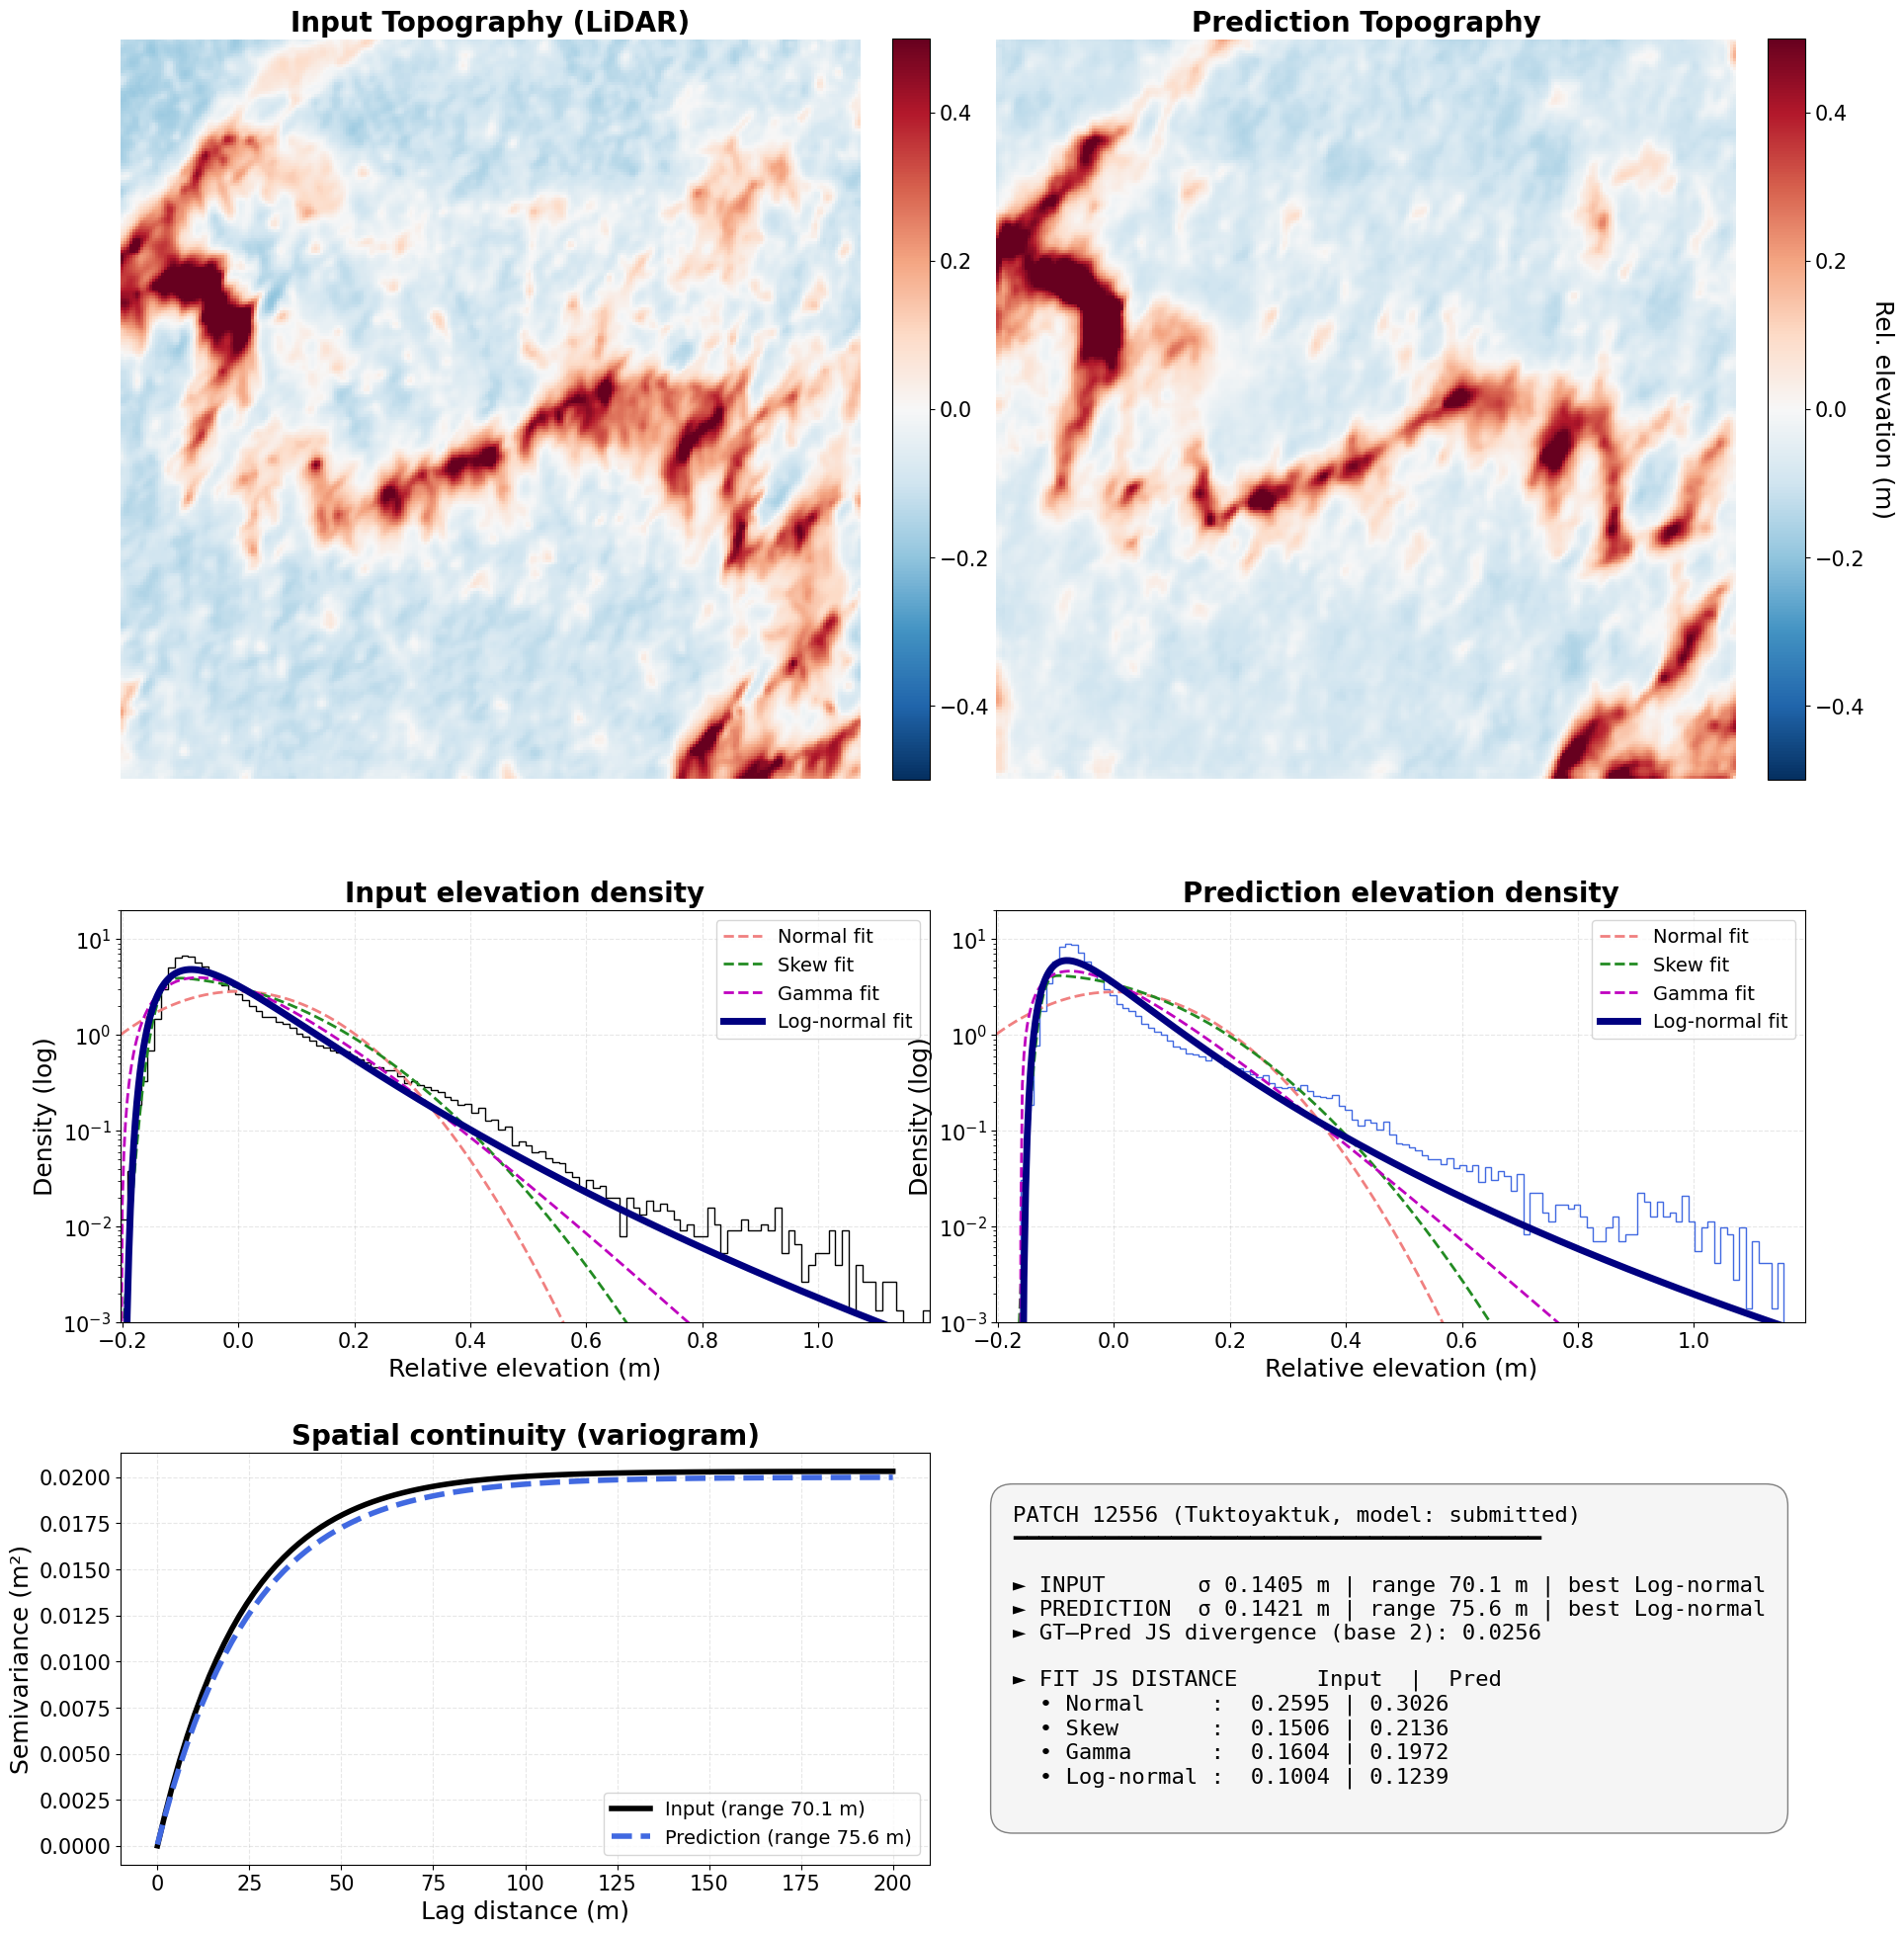

In [13]:
import matplotlib.pyplot as plt
REGION_COLORS = {'pondinlet': '#2a78d6', 'tuk': '#eb6834', 'cambridge': '#1baf7a'}   # validated categorical slots 1-3
REGION_MARKERS = {'pondinlet': 'o', 'tuk': 's', 'cambridge': '^'}
FAM_COLORS = {'Normal': 'lightcoral', 'Skew': 'forestgreen', 'Gamma': 'm', 'Log-normal': 'navy'}   # as in the paper

def fig5_patch(set_name=MAIN_SET, region=FIG5_REGION, pid=FIG5_PID, save=True):
    gt_path = os.path.join(REGIONS[region]['lidar_dir'], f'lidar_patch_{pid}.tif')
    pr_path = [f for f in glob.glob(os.path.join(PRED_SETS[set_name][region], '*.tif')) if patch_id(f) == pid][0]
    gt, pr, m = read_pair(gt_path, pr_path)
    mu_g, mu_p = gt[m].mean(), pr[m].mean(); g, p = gt[m] - mu_g, pr[m] - mu_p
    fg, bg, sg = fit_families(g, n_fit=len(g)); fp, bp, sp = fit_families(p, n_fit=len(p))
    _, vg = compute_variogram(np.where(m, gt - mu_g, 0), m, VARIO_N_FIG5); _, vp = compute_variogram(np.where(m, pr - mu_p, 0), m, VARIO_N_FIG5)
    plt.rcParams.update({'font.family': 'sans-serif', 'axes.labelsize': 18, 'axes.titlesize': 20, 'xtick.labelsize': 15, 'ytick.labelsize': 15, 'legend.fontsize': 14})
    fig = plt.figure(figsize=(22, 24)); gs = fig.add_gridspec(3, 4, height_ratios=[3.6, 2.0, 2.0], hspace=0.25, wspace=0.18)
    for i, (arr, mu, title) in enumerate([(gt, mu_g, 'Input Topography (LiDAR)'), (pr, mu_p, 'Prediction Topography')]):
        ax = fig.add_subplot(gs[0, 2 * i:2 * i + 2])
        im = ax.imshow(np.rot90(np.ma.masked_where(~m, arr - mu), k=1), cmap='RdBu_r', vmin=-0.5, vmax=0.5, interpolation='nearest')
        ax.set_title(title, fontweight='bold'); ax.set_axis_off()
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).ax.set_ylabel('Rel. elevation (m)', rotation=270, labelpad=22)
    lo, hi = min(g.min(), p.min()), max(g.max(), p.max()); x = np.linspace(lo, hi, 500)
    for i, (dat, key, fts, best, sh, col) in enumerate([(g, 'Input', fg, bg, sg, 'black'), (p, 'Prediction', fp, bp, sp, 'royalblue')]):
        ax = fig.add_subplot(gs[1, 2 * i:2 * i + 2]); ax.hist(dat, bins=120, density=True, histtype='step', color=col, lw=3)
        for fam in FAMILIES:
            pr_ = fts[fam]['params']
            y = family_pdf(fam, pr_, x, sh)
            ax.plot(x, y, color=FAM_COLORS[fam], lw=5 if fam == best else 2, ls='-' if fam == best else '--', label=f'{fam} fit')
        ax.set_yscale('log'); ax.set_xlim(lo, hi); ax.set_ylim(1e-3, 20); ax.set_xlabel('Relative elevation (m)'); ax.set_ylabel('Density (log)')
        ax.set_title(f'{key} elevation density', fontweight='bold'); ax.legend(loc='upper right'); ax.grid(alpha=.3, ls='--')
    ax = fig.add_subplot(gs[2, 0:2]); h = np.linspace(0, 200, 100)
    ax.plot(h, exp_variogram(h, *vg), 'k-', lw=4, label=f'Input (range {vg[2]:.1f} m)'); ax.plot(h, exp_variogram(h, *vp), color='royalblue', ls='--', lw=4, label=f'Prediction (range {vp[2]:.1f} m)')
    ax.set_xlabel('Lag distance (m)'); ax.set_ylabel('Semivariance (m²)'); ax.set_title('Spatial continuity (variogram)', fontweight='bold'); ax.legend(loc='lower right'); ax.grid(alpha=.3, ls='--')
    ax = fig.add_subplot(gs[2, 2:4]); ax.axis('off')
    txt = (f'PATCH {pid} ({REGIONS[region]["name"]}, model: {set_name})\n' + '━' * 40 + '\n\n'
           f'► INPUT       σ {g.std():.4f} m | range {vg[2]:.1f} m | best {bg}\n'
           f'► PREDICTION  σ {p.std():.4f} m | range {vp[2]:.1f} m | best {bp}\n'
           f'► GT–Pred JS divergence (base 2): {jsd_base2(g, p):.4f}\n\n'
           f'► FIT JS DISTANCE      Input  |  Pred\n' +
           ''.join(f'  • {fam:<11}:  {fg[fam]["jsd"]:.4f} | {fp[fam]["jsd"]:.4f}\n' for fam in FAMILIES))
    ax.text(0.02, 0.5, txt, family='monospace', fontsize=16, va='center', transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=1.0', facecolor='whitesmoke', edgecolor='gray'))
    if save:
        fig.savefig(f'{OUT_DIR}/Fig5_patch{pid}_{set_name}.png', dpi=300, bbox_inches='tight')
    plt.show()
    return dict(sigma_gt=g.std(), sigma_pr=p.std(), range_gt=vg[2], range_pr=vp[2], best_gt=bg, best_pr=bp)

FIG5_STATS = fig5_patch()

## B6. Figure 5 extended (all patches, all regions)

(a) Patch RMS height, prediction vs LiDAR. (b) Variogram effective range; the shaded band lies beyond the 200 m maximum lag, so fits there are unconstrained. (c) Pooled regional elevation PDFs, LiDAR solid and prediction dashed. (d) Per-patch GT–prediction JS divergence, with the Fig. 5 patch starred and its within-region percentile shown. (e) Share of patches whose best-fitting family is each candidate, LiDAR (open) vs prediction (filled). (f) Roughness-class agreement, row-normalised over all regions.

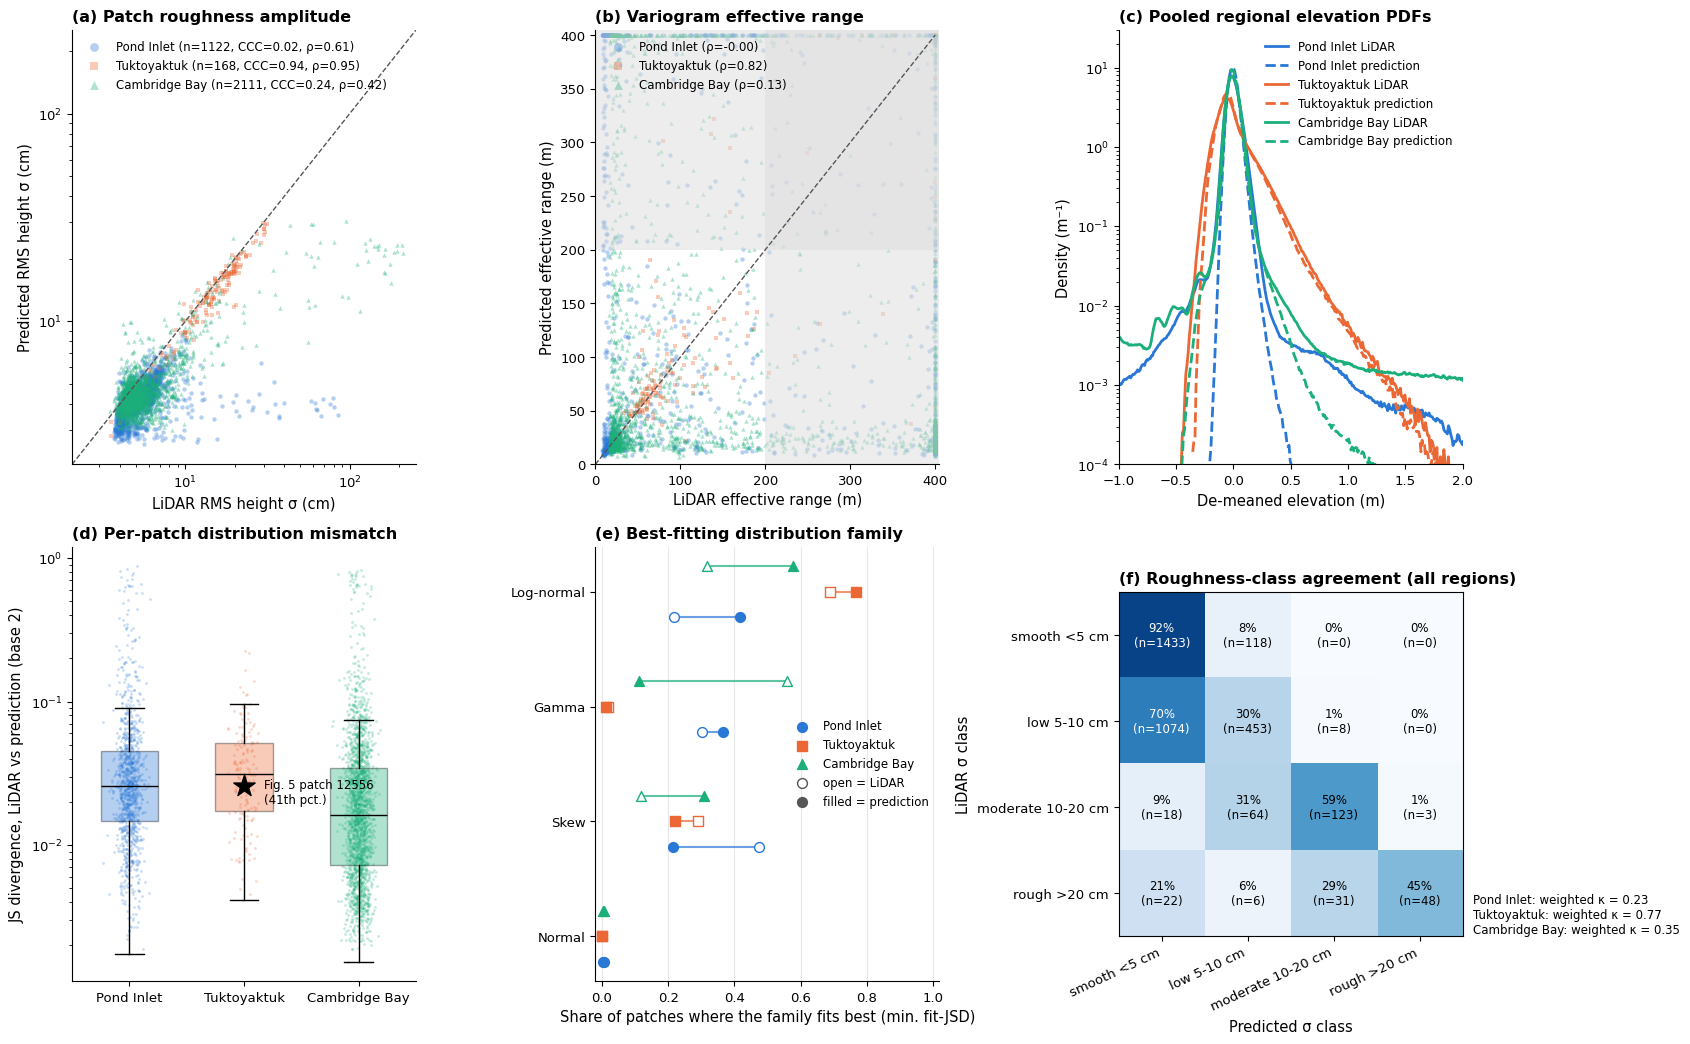

In [14]:
# B6. Extended figure
def fig5_extended(set_name=MAIN_SET, save=True):
    df, arrs = RESULTS[set_name], ARRAYS[set_name]
    regions = [r for r in REGIONS if r in set(df.region)]
    plt.rcdefaults()
    plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                         'axes.labelsize': 10.5, 'legend.fontsize': 8.5, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5})
    fig, axs = plt.subplots(2, 3, figsize=(17, 11)); A = axs.ravel()
    # (a) sigma
    for r in regions:
        d = df[df.region == r]
        A[0].scatter(100 * d.sigma_gt, 100 * d.sigma_pr, s=10, alpha=.35, c=REGION_COLORS[r], marker=REGION_MARKERS[r], linewidths=0,
                     label=f"{REGIONS[r]['name']} (n={len(d)}, CCC={lin_ccc(d.sigma_gt, d.sigma_pr):.2f}, ρ={stats.spearmanr(d.sigma_gt, d.sigma_pr)[0]:.2f})")
    lim = [max(0.5, 100 * df[['sigma_gt', 'sigma_pr']].min().min() * .8), 100 * df[['sigma_gt', 'sigma_pr']].max().max() * 1.2]
    A[0].plot(lim, lim, color='#555', lw=1, ls='--'); A[0].set(xscale='log', yscale='log', xlim=lim, ylim=lim,
              xlabel='LiDAR RMS height σ (cm)', ylabel='Predicted RMS height σ (cm)', title='(a) Patch roughness amplitude')
    A[0].legend(loc='upper left', markerscale=2, frameon=False)
    # (b) range
    for r in regions:
        d = df[df.region == r]
        A[1].scatter(d.range_gt, d.range_pr, s=10, alpha=.35, c=REGION_COLORS[r], marker=REGION_MARKERS[r], linewidths=0,
                     label=f"{REGIONS[r]['name']} (ρ={stats.spearmanr(d.range_gt, d.range_pr)[0]:.2f})")
    A[1].axvspan(200, 410, color='#ddd', alpha=.5, lw=0); A[1].axhspan(200, 410, color='#ddd', alpha=.5, lw=0)
    A[1].plot([0, 400], [0, 400], color='#555', lw=1, ls='--')
    A[1].set(xlim=(0, 405), ylim=(0, 405), xlabel='LiDAR effective range (m)', ylabel='Predicted effective range (m)', title='(b) Variogram effective range')
    A[1].legend(loc='upper left', markerscale=2, frameon=False)
    # (c) pooled PDFs
    c = 0.5 * (H_EDGES[:-1] + H_EDGES[1:])
    for r in regions:
        hg, hp = arrs[r]['hist_gt'] / arrs[r]['hist_gt'].sum() / 0.01, arrs[r]['hist_pr'] / arrs[r]['hist_pr'].sum() / 0.01
        A[2].plot(c, np.where(hg > 0, hg, np.nan), color=REGION_COLORS[r], lw=2, label=f"{REGIONS[r]['name']} LiDAR")
        A[2].plot(c, np.where(hp > 0, hp, np.nan), color=REGION_COLORS[r], lw=2, ls='--', label=f"{REGIONS[r]['name']} prediction")
    A[2].set(yscale='log', xlim=(-1, 2), ylim=(1e-4, 30), xlabel='De-meaned elevation (m)', ylabel='Density (m⁻¹)', title='(c) Pooled regional elevation PDFs')
    A[2].legend(frameon=False, ncol=1)
    # (d) JSD distribution + Fig.5 patch
    data = [df[df.region == r].jsd_gt_pred.values for r in regions]
    bp = A[3].boxplot(data, vert=True, widths=.5, showfliers=False, patch_artist=True, medianprops=dict(color='black'))
    for patch, r in zip(bp['boxes'], regions):
        patch.set(facecolor=REGION_COLORS[r], alpha=.35)
    for i, r in enumerate(regions):
        v = df[df.region == r].jsd_gt_pred.values
        A[3].scatter(np.random.default_rng(0).normal(i + 1, .06, len(v)), v, s=4, color=REGION_COLORS[r], alpha=.25, linewidths=0)
    f5 = df[(df.region == FIG5_REGION) & (df.pid == FIG5_PID)]
    if len(f5):
        xi = regions.index(FIG5_REGION) + 1; v = f5.jsd_gt_pred.iloc[0]
        pct = stats.percentileofscore(df[df.region == FIG5_REGION].jsd_gt_pred, v)
        A[3].scatter([xi], [v], marker='*', s=260, color='black', zorder=5)
        A[3].annotate(f'Fig. 5 patch {FIG5_PID}\n({pct:.0f}th pct.)', (xi, v), xytext=(14, -4), textcoords='offset points', fontsize=8.5, va='center')
    A[3].set_xticks(range(1, len(regions) + 1), [REGIONS[r]['name'] for r in regions])
    A[3].set(yscale='log', ylabel='JS divergence, LiDAR vs prediction (base 2)', title='(d) Per-patch distribution mismatch')
    # (e) best-family dumbbell
    for j, r in enumerate(regions):
        d = df[df.region == r]
        for k, fam in enumerate(FAMILIES):
            y = k + (j - 1) * 0.22; a, b = (d.best_gt == fam).mean(), (d.best_pr == fam).mean()
            A[4].plot([a, b], [y, y], color=REGION_COLORS[r], lw=1.5, alpha=.7)
            A[4].scatter([a], [y], facecolors='white', edgecolors=REGION_COLORS[r], s=50, zorder=3, marker=REGION_MARKERS[r])
            A[4].scatter([b], [y], color=REGION_COLORS[r], s=50, zorder=3, marker=REGION_MARKERS[r], label=REGIONS[r]['name'] if k == 0 else None)
    A[4].scatter([], [], facecolors='white', edgecolors='#555', s=50, label='open = LiDAR')
    A[4].scatter([], [], color='#555', s=50, label='filled = prediction')
    A[4].set_yticks(range(len(FAMILIES)), FAMILIES); A[4].set(xlim=(-.02, 1.02), xlabel='Share of patches where the family fits best (min. fit-JSD)', title='(e) Best-fitting distribution family')
    A[4].legend(frameon=False, loc='center right'); A[4].grid(axis='x', alpha=.3)
    # (f) class confusion
    K = len(SIGMA_CLASS_LABELS); cm = np.zeros((K, K))
    for a, b in zip(df.class_gt, df.class_pr):
        cm[int(a), int(b)] += 1
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    A[5].imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i_ in range(K):
        for j_ in range(K):
            A[5].text(j_, i_, f'{100*cmn[i_, j_]:.0f}%\n(n={int(cm[i_, j_])})', ha='center', va='center', fontsize=8.5,
                      color='white' if cmn[i_, j_] > .6 else 'black')
    lbl = [l.replace('\n', ' ') for l in SIGMA_CLASS_LABELS]
    A[5].set_xticks(range(K), lbl, rotation=25, ha='right'); A[5].set_yticks(range(K), lbl)
    kap = '\n'.join(f"{REGIONS[r]['name']}: weighted κ = {kappa(df[df.region==r].class_gt, df[df.region==r].class_pr):.2f}" for r in regions)
    A[5].set(xlabel='Predicted σ class', ylabel='LiDAR σ class', title='(f) Roughness-class agreement (all regions)')
    A[5].text(1.03, 0.0, kap, transform=A[5].transAxes, fontsize=8.5, va='bottom')
    for ax in A[:5]:
        ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    if save:
        for ext in ('png', 'pdf'):
            fig.savefig(f'{OUT_DIR}/Fig5_extended_{set_name}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()

fig5_extended()

## B7. How representative is the Fig. 5 patch, and how much do stochastic realisations vary?

In [15]:
# B7a. Percentile of the Fig. 5 patch within its region, for each metric
df = RESULTS[MAIN_SET]; d = df[df.region == FIG5_REGION]; f5 = d[d.pid == FIG5_PID]
if len(f5):
    f5 = f5.iloc[0]
    rep = pd.DataFrame({
        'metric': ['σ_GT (m)', 'σ_pred/σ_GT', 'range_GT (m)', 'range_pred/range_GT', 'JSD GT–pred', 'W1 (m)', 'RMSE (m)'],
        'patch':  [f5.sigma_gt, f5.sigma_pr / f5.sigma_gt, f5.range_gt, f5.range_pr / f5.range_gt, f5.jsd_gt_pred, f5.w1_gt_pred, f5.rmse],
        'region median': [d.sigma_gt.median(), (d.sigma_pr / d.sigma_gt).median(), d.range_gt.median(), (d.range_pr / d.range_gt).median(),
                          d.jsd_gt_pred.median(), d.w1_gt_pred.median(), d.rmse.median()]})
    rep['percentile in region'] = [stats.percentileofscore(s, v) for s, v in zip(
        [d.sigma_gt, d.sigma_pr / d.sigma_gt, d.range_gt, d.range_pr / d.range_gt, d.jsd_gt_pred, d.w1_gt_pred, d.rmse], rep.patch)]
    rep.to_csv(f'{OUT_DIR}/fig5_patch_representativeness_{MAIN_SET}.csv', index=False)
    display(rep.round(4)) if 'display' in globals() else print(rep.round(4))
else:
    print(f'Patch {FIG5_PID} not in {MAIN_SET} results')

# B7b. Ensemble spread for the Fig. 5 patch (from A4)
ens_files = sorted(glob.glob(f'{OUT_DIR}/ensemble_{FIG5_REGION}_{FIG5_PID}/pred_*_r*.tif'))
if ens_files:
    gt_path = os.path.join(REGIONS[FIG5_REGION]['lidar_dir'], f'lidar_patch_{FIG5_PID}.tif')
    rows = []
    for f in ens_files:
        gt, pr, m = read_pair(gt_path, f); g, p = gt[m] - gt[m].mean(), pr[m] - pr[m].mean()
        _, vp = compute_variogram(np.where(m, pr - pr[m].mean(), 0), m, VARIO_N_FIG5)
        rows.append(dict(member=re.findall(r'_r(\d+)', f)[-1], sigma=p.std(), range=vp[2], jsd=jsd_base2(g, p), best=fit_families(p)[1]))
    ens = pd.DataFrame(rows); _, vg = compute_variogram(np.where(m, gt - gt[m].mean(), 0), m, VARIO_N_FIG5)
    print(f'GT: σ={g.std():.4f} m, range={vg[2]:.1f} m, best={fit_families(g)[1]}')
    print(f'Ensemble (n={len(ens)}): σ={ens.sigma.mean():.4f}±{ens.sigma.std():.4f} m, range={ens.range.mean():.1f}±{ens.range.std():.1f} m, '
          f'JSD={ens.jsd.mean():.4f}±{ens.jsd.std():.4f}; best-family counts: {ens.best.value_counts().to_dict()}')
    ens.to_csv(f'{OUT_DIR}/fig5_patch_ensemble.csv', index=False)

                metric    patch  region median  percentile in region
0             σ_GT (m)   0.1405         0.1514               42.2619
1          σ_pred/σ_GT   1.0117         0.9143               89.2857
2         range_GT (m)  69.2657        78.8746               40.4762
3  range_pred/range_GT   1.1242         1.0000               75.0000
4          JSD GT–pred   0.0256         0.0311               41.0714
5               W1 (m)   0.0127         0.0123               51.7857
6             RMSE (m)   0.0766         0.0971               25.0000


In [16]:
# B8. (Optional) submitted vs final model, side by side
if len(TABLES) > 1:
    both = pd.concat(TABLES, axis=1)
    both.to_csv(f'{OUT_DIR}/regional_table_submitted_vs_final.csv')
    display(both) if 'display' in globals() else print(both)